# Balas-Simonetti Intra-Route Local Search: Baseline (k=3) vs. NONE vs. UNRESTRICTED

This notebook is a **lean, paper-oriented** comparison of three ALNS variants on the same
**20 MD-DARP instances x 20 seeds**, differing only in the intra-route local search applied
mid-ALNS (a hill-climbing procedure based on Balas-Simonetti neighborhoods):

- **Baseline (k=3)**: the original ALNS run, `./run_base_20/` (Balas-Simonetti with `k=3`).
- **NONE**: intra-route local search disabled, `./run_intra_route/` (`--intraRoute NONE`).
- **UNRESTRICTED**: intra-route local search with an unrestricted neighborhood,
  `./run_intra_route/` (`--intraRoute UNRESTRICTED`).

All three variants share the same instance/seed grid, so results are pooled per instance
across variants and RPD is computed against a **BKR**.

This notebook intentionally keeps a small number of tables (one main comparison table with
an aggregated row, plus a short "who wins" summary) and two figures (a mean-RPD bar chart and
a convergence overlay), rather than the full exploratory sweep used in earlier notebooks.

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

BASE_DIR = Path("../data/run_base_20")
INTRA_DIR = Path("../data/run_intra_route")

VARIANT_ORDER = ["Baseline (k=3)", "NONE", "UNRESTRICTED"]
VARIANT_COLORS = {
    "Baseline (k=3)": "tab:blue",
    "NONE": "tab:red",
    "UNRESTRICTED": "tab:green",
}

EXPECTED_INSTANCES = [
    "md1a", "md2a", "md3a", "md4a", "md5a",
    "md6a", "md7a", "md8a", "md9a", "md10a",
    "md1b", "md2b", "md3b", "md4b", "md5b",
    "md6b", "md7b", "md8b", "md9b", "md10b",
]
EXPECTED_SEEDS = range(1, 21)

COMPARISON_DIR = Path("../results/intra_route")
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["figure.dpi"] = 120

print(f"Baseline dir:    {BASE_DIR.resolve()}")
print(f"Intra-route dir: {INTRA_DIR.resolve()}")


Baseline dir:    /home/guillem/MD-DARP-Research/experiments/data/run_base_20
Intra-route dir: /home/guillem/MD-DARP-Research/experiments/data/run_intra_route


## 1. Load all three variants

Only convergence logs and final-solution JSONs are loaded (weight-evolution logs are not
needed for this comparison, which keeps loading fast and the notebook focused).

In [2]:
# ---------------------------------------------------------
# Filename patterns
#   Baseline:    log_md1a_seed1_convergence.csv        sol_md1a_seed1.json
#   Intra-route: log_md1a_seed_1_NONE_convergence.csv   sol_md1a_seed_1_NONE.json
# ---------------------------------------------------------

BASE_CONV_PATTERN = re.compile(r"^log_?(.+?)_?seed(\d+)_convergence\.csv$")
BASE_SOL_PATTERN = re.compile(r"^sol_?(.+?)_?seed(\d+)\.json$")

INTRA_CONV_PATTERN = re.compile(r"^log_(.+)_seed_(\d+)_(NONE|UNRESTRICTED)_convergence\.csv$")
INTRA_SOL_PATTERN = re.compile(r"^sol_(.+)_seed_(\d+)_(NONE|UNRESTRICTED)\.json$")


def load_convergence(files, pattern, variant_label, has_mode=False):
    required_cols = {
        "iteration", "elapsed_time", "current_obj", "best_obj",
        "best_feasible_obj", "destroy_op", "repair_op", "reward",
        "temperature", "segment",
    }

    frames = []
    for path in files:
        m = pattern.match(path.name)
        if not m:
            continue
        instance, seed = m.group(1), int(m.group(2))
        variant = m.group(3) if has_mode else variant_label

        try:
            df = pd.read_csv(path)
        except Exception as exc:
            warnings.warn(f"Could not read {path}: {exc}")
            continue

        missing = required_cols - set(df.columns)
        if missing:
            warnings.warn(f"{path.name}: missing columns {sorted(missing)}")
            continue

        df["instance"] = instance
        df["seed"] = seed
        df["variant"] = variant
        df["run_id"] = f"{instance}_seed{seed}_{variant}"

        for col in required_cols:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        df["best_feasible_obj"] = df["best_feasible_obj"].replace([np.inf, -np.inf], np.nan)

        frames.append(df)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def load_solutions(files, pattern, variant_label, has_mode=False):
    rows = []
    for path in files:
        m = pattern.match(path.name)
        if not m:
            continue
        instance, seed = m.group(1), int(m.group(2))
        variant = m.group(3) if has_mode else variant_label

        try:
            with open(path, "r") as f:
                data = json.load(f)
        except Exception as exc:
            warnings.warn(f"Could not read {path}: {exc}")
            continue

        summary = data.get("summary", {}) if isinstance(data, dict) else {}
        rows.append({
            "instance": instance,
            "seed": seed,
            "variant": variant,
            "run_id": f"{instance}_seed{seed}_{variant}",
            "num_requests": summary.get("num_requests"),
            "num_vehicles": summary.get("num_vehicles"),
        })

    df = pd.DataFrame(rows)
    if not df.empty:
        for col in ["num_requests", "num_vehicles"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def check_completeness(name, discovered_runs):
    missing = [
        (inst, seed) for inst in EXPECTED_INSTANCES for seed in EXPECTED_SEEDS
        if (inst, seed) not in discovered_runs
    ]
    print(f"[{name}] unique runs discovered: {len(discovered_runs)}", end="")
    if missing:
        print(f"  -- MISSING {len(missing)} runs, e.g. {missing[:5]}")
    else:
        print("  -- complete (20 x 20)")


In [3]:
# ---------------------------------------------------------
# Discover files
# ---------------------------------------------------------

base_conv_files = sorted((BASE_DIR / "alns_logs").glob("*convergence.csv"))
base_sol_files = sorted((BASE_DIR / "outputs").glob("*.json"))

intra_conv_files = sorted((INTRA_DIR / "alns_logs").glob("*convergence.csv"))
intra_sol_files = sorted((INTRA_DIR / "outputs").glob("*.json"))

print(f"Baseline:    {len(base_conv_files)} convergence logs, {len(base_sol_files)} solution JSONs")
print(f"Intra-route: {len(intra_conv_files)} convergence logs, {len(intra_sol_files)} solution JSONs "
      "(NONE + UNRESTRICTED combined)\n")

# Completeness per variant
base_runs = sorted({(m.group(1), int(m.group(2)))
                     for p in base_conv_files if (m := BASE_CONV_PATTERN.match(p.name))})
check_completeness("Baseline (k=3)", base_runs)

for mode in ["NONE", "UNRESTRICTED"]:
    mode_runs = sorted({
        (m.group(1), int(m.group(2)))
        for p in intra_conv_files
        if (m := INTRA_CONV_PATTERN.match(p.name)) and m.group(3) == mode
    })
    check_completeness(mode, mode_runs)


Baseline:    400 convergence logs, 400 solution JSONs
Intra-route: 800 convergence logs, 800 solution JSONs (NONE + UNRESTRICTED combined)

[Baseline (k=3)] unique runs discovered: 400  -- complete (20 x 20)
[NONE] unique runs discovered: 400  -- complete (20 x 20)
[UNRESTRICTED] unique runs discovered: 400  -- complete (20 x 20)


In [4]:
# ---------------------------------------------------------
# Load convergence + solutions for all three variants and combine
# ---------------------------------------------------------

df_conv_base = load_convergence(base_conv_files, BASE_CONV_PATTERN, "Baseline (k=3)", has_mode=False)
df_conv_intra = load_convergence(intra_conv_files, INTRA_CONV_PATTERN, None, has_mode=True)
df_conv_all = pd.concat([df_conv_base, df_conv_intra], ignore_index=True)

df_sol_base = load_solutions(base_sol_files, BASE_SOL_PATTERN, "Baseline (k=3)", has_mode=False)
df_sol_intra = load_solutions(intra_sol_files, INTRA_SOL_PATTERN, None, has_mode=True)
df_solutions_all = pd.concat([df_sol_base, df_sol_intra], ignore_index=True)

print(f"Total convergence rows: {len(df_conv_all):,} across {df_conv_all['run_id'].nunique()} runs")
display(df_conv_all[["instance", "seed", "variant", "iteration", "best_feasible_obj"]].head())


Total convergence rows: 11,998,128 across 1200 runs


,instance,seed,variant,iteration,best_feasible_obj
0,md10a,10,Baseline (k=3),0,NaN
1,md10a,10,Baseline (k=3),1,NaN
2,md10a,10,Baseline (k=3),2,NaN
3,md10a,10,Baseline (k=3),3,NaN
4,md10a,10,Baseline (k=3),4,NaN


## 2. Run-level summary and BKR reference

In [5]:
# ---------------------------------------------------------
# One row per (instance, seed, variant) run + BKR reference
# ---------------------------------------------------------

run_rows = []
for (instance, seed, variant), g in df_conv_all.groupby(["instance", "seed", "variant"], sort=False):
    g = g.sort_values("iteration")
    feasible = g["best_feasible_obj"].dropna()
    run_rows.append({
        "instance": instance,
        "seed": seed,
        "variant": variant,
        "elapsed_time_sec": g["elapsed_time"].max(),
        "best_feasible_objective": feasible.min() if not feasible.empty else np.nan,
    })

df_runs_all = pd.DataFrame(run_rows)
df_runs_all = df_runs_all.merge(
    df_solutions_all[["instance", "seed", "variant", "num_requests", "num_vehicles"]],
    on=["instance", "seed", "variant"], how="left",
)

df_runs_all["regime"] = df_runs_all["instance"].str[-1].str.upper()
df_runs_all["size_id"] = df_runs_all["instance"].str.extract(r"md(\d+)[ab]", expand=False).astype(int)

import warnings
from utils import BKR

# BKR reference per instance (replaces the old joint best across variants)
bkr_reference = pd.DataFrame({"instance": list(BKR.keys()), "bkr": list(BKR.values())})
df_runs_all = df_runs_all.merge(bkr_reference, on="instance", how="left")

# Check 1: instances without a BKR
missing_bkr = sorted(df_runs_all.loc[df_runs_all["bkr"].isna(), "instance"].unique())
if missing_bkr:
    warnings.warn(f"No BKR found for instances: {missing_bkr}")

# Check 2: infeasible / NaN / infinite runs
bad = ~np.isfinite(df_runs_all["best_feasible_objective"].astype(float))
if bad.any():
    warnings.warn(
        f"{bad.sum()} run(s) have no feasible solution (NaN/inf objective):\n"
        + df_runs_all.loc[bad, ["instance", "seed", "variant"]].to_string(index=False)
    )

df_runs_all["RPD_percent"] = (
    100 * (df_runs_all["best_feasible_objective"] - df_runs_all["bkr"]) / df_runs_all["bkr"]
)
print(f"Total runs loaded: {len(df_runs_all)}  (expect {len(EXPECTED_INSTANCES) * len(list(EXPECTED_SEEDS)) * 3})")
display(df_runs_all.groupby("variant").size().rename("runs").to_frame())


Total runs loaded: 1200  (expect 1200)


,runs
variant,
Baseline (k=3),400
NONE,400
UNRESTRICTED,400


## 3. Main comparison table

Per-instance mean RPD and mean runtime for each variant, with a final **aggregated** row
(pooled mean across all runs/instances).

In [6]:
# ---------------------------------------------------------
# Main comparison table: per instance + aggregate row
# ---------------------------------------------------------

per_instance = (
    df_runs_all
    .groupby(["instance", "regime", "size_id", "variant"])
    .agg(
        mean_RPD=("RPD_percent", "mean"),
        mean_best_feasible_objective=("best_feasible_objective", "mean"),
        mean_runtime_sec=("elapsed_time_sec", "mean"))
    .reset_index()
)

pivot_rpd = per_instance.pivot(index=["instance", "regime", "size_id"], columns="variant", values="mean_RPD")
pivot_obj = per_instance.pivot(index=["instance", "regime", "size_id"], columns="variant", values="mean_best_feasible_objective")
pivot_rt = per_instance.pivot(index=["instance", "regime", "size_id"], columns="variant", values="mean_runtime_sec")

pivot_rpd = pivot_rpd[VARIANT_ORDER].add_suffix(" - RPD (%)")
pivot_obj = pivot_obj[VARIANT_ORDER].add_suffix(" - best feasible objective")
pivot_rt = pivot_rt[VARIANT_ORDER].add_suffix(" - runtime (s)")

main_table = pivot_rpd.join([pivot_obj, pivot_rt]).reset_index().sort_values(["regime", "size_id"])

# Aggregate row: pooled mean across ALL runs (all instances, all seeds)
agg_row = {"instance": "ALL (aggregated)", "regime": "-", "size_id": np.nan}
for v in VARIANT_ORDER:
    agg_row[f"{v} - RPD (%)"] = df_runs_all.loc[df_runs_all["variant"] == v, "RPD_percent"].mean()
    agg_row[f"{v} - best feasible objective"] = df_runs_all.loc[df_runs_all["variant"] == v, "best_feasible_objective"].mean()
    agg_row[f"{v} - runtime (s)"] = df_runs_all.loc[df_runs_all["variant"] == v, "elapsed_time_sec"].mean()

main_table = pd.concat([main_table, pd.DataFrame([agg_row])], ignore_index=True)

display(main_table.round(3))
display(
    main_table[
        [ "instance", "Baseline (k=3) - RPD (%)", "UNRESTRICTED - RPD (%)", "NONE - RPD (%)",
         "Baseline (k=3) - runtime (s)", "UNRESTRICTED - runtime (s)", "NONE - runtime (s)"]
        ]
        .rename(columns={
            "Baseline (k=3) - runtime (s)": "Baseline (k=3) - runtime (m)",
            "NONE - runtime (s)": "NONE - runtime (m)",
            "UNRESTRICTED - runtime (s)": "UNRESTRICTED - runtime (m)"
        })
        .assign(**{
            "Baseline (k=3) - runtime (m)": lambda df: df["Baseline (k=3) - runtime (m)"] / 60,
            "NONE - runtime (m)": lambda df: df["NONE - runtime (m)"] / 60,
            "UNRESTRICTED - runtime (m)": lambda df: df["UNRESTRICTED - runtime (m)"] / 60
        })
        .round(2)
)
    


,instance,regime,size_id,Baseline (k=3) - RPD (%),NONE - RPD (%),UNRESTRICTED - RPD (%),Baseline (k=3) - best feasible objective,NONE - best feasible objective,UNRESTRICTED - best feasible objective,Baseline (k=3) - runtime (s),NONE - runtime (s),UNRESTRICTED - runtime (s)
0,md1a,A,1.0,0.039,0.021,0.022,308.687,308.632,308.635,47.008,40.972,60.049
1,md2a,A,2.0,2.581,2.984,2.490,539.162,541.280,538.683,303.592,287.858,339.703
2,md3a,A,3.0,2.418,2.285,2.277,695.180,694.273,694.220,880.224,919.765,1003.051
3,md4a,A,4.0,2.028,1.783,1.599,840.140,838.122,836.608,1832.086,2004.854,1994.478
4,md5a,A,5.0,3.838,3.074,4.142,1016.989,1009.512,1019.968,3041.188,3193.026,3250.346
5,md6a,A,6.0,2.128,2.341,1.965,1214.446,1216.982,1212.506,4883.856,5163.234,5221.564
6,md7a,A,7.0,1.593,1.536,2.036,406.156,405.929,407.925,167.388,151.347,174.171
7,md8a,A,8.0,4.277,4.838,3.533,748.784,752.813,743.440,1249.984,1346.584,1383.258
8,md9a,A,9.0,1.822,2.396,1.836,891.973,896.998,892.094,2608.468,2624.011,2636.874
9,md10a,A,10.0,4.115,4.495,4.863,1190.039,1194.380,1198.592,6046.314,5952.356,6016.121


,instance,Baseline (k=3) - RPD (%),UNRESTRICTED - RPD (%),NONE - RPD (%),Baseline (k=3) - runtime (m),UNRESTRICTED - runtime (m),NONE - runtime (m)
0,md1a,0.04,0.02,0.02,0.78,1.00,0.68
1,md2a,2.58,2.49,2.98,5.06,5.66,4.80
2,md3a,2.42,2.28,2.28,14.67,16.72,15.33
3,md4a,2.03,1.60,1.78,30.53,33.24,33.41
4,md5a,3.84,4.14,3.07,50.69,54.17,53.22
5,md6a,2.13,1.96,2.34,81.40,87.03,86.05
6,md7a,1.59,2.04,1.54,2.79,2.90,2.52
7,md8a,4.28,3.53,4.84,20.83,23.05,22.44
8,md9a,1.82,1.84,2.40,43.47,43.95,43.73
9,md10a,4.12,4.86,4.49,100.77,100.27,99.21


In [7]:
# Remove runs without a feasible solution
valid_runs = df_runs_all.dropna(subset=["best_feasible_objective"]).copy()

# For each (instance, variant), find the run with the best objective.
# If multiple seeds achieve the same objective, take the fastest one.
best_idx = (
    valid_runs
    .sort_values(
        ["instance", "variant",
         "best_feasible_objective", "elapsed_time_sec",
         "seed"]
    )
    .groupby(["instance", "variant"], as_index=False)
    .head(1)
)

# Keep only the relevant columns
best_per_instance = best_idx[
    [
        "instance",
        "variant",
        "seed",
        "best_feasible_objective",
        "elapsed_time_sec",
    ]
].copy()

# Pivot objective
pivot_best_obj = (
    best_per_instance
    .pivot(
        index="instance",
        columns="variant",
        values="best_feasible_objective"
    )
    .reindex(columns=VARIANT_ORDER)
    .add_suffix(" - best objective")
)

# Pivot runtime corresponding to the best objective
pivot_best_time = (
    best_per_instance
    .pivot(
        index="instance",
        columns="variant",
        values="elapsed_time_sec"
    )
    .reindex(columns=VARIANT_ORDER)
    .add_suffix(" - runtime (s)")
)

# Pivot seed that achieved the best objective
pivot_best_seed = (
    best_per_instance
    .pivot(
        index="instance",
        columns="variant",
        values="seed"
    )
    .reindex(columns=VARIANT_ORDER)
    .add_suffix(" - seed")
)

# Combine
best_table = (
    pivot_best_obj
    .join([pivot_best_time, pivot_best_seed])
    .reset_index()
)

# Add regime and size
best_table["regime"] = best_table["instance"].str[-1].str.upper()
best_table["size_id"] = (
    best_table["instance"]
    .str.extract(r"md(\d+)[ab]", expand=False)
    .astype(int)
)

# Sort
best_table = best_table.sort_values(
    ["regime", "size_id", "instance"]
)

# Reorder columns
best_table = best_table[
    ["instance", "regime", "size_id"]
    + [f"{v} - best objective" for v in VARIANT_ORDER]
    + [f"{v} - runtime (s)" for v in VARIANT_ORDER]
    + [f"{v} - seed" for v in VARIANT_ORDER]
]

display(best_table.round(3))

variant,instance,regime,size_id,Baseline (k=3) - best objective,NONE - best objective,UNRESTRICTED - best objective,Baseline (k=3) - runtime (s),NONE - runtime (s),UNRESTRICTED - runtime (s),Baseline (k=3) - seed,NONE - seed,UNRESTRICTED - seed
2,md1a,A,1,308.567,308.567,308.567,40.273,37.191,45.076,7,19,9
4,md2a,A,2,530.014,532.551,529.932,276.517,258.107,291.430,18,16,5
6,md3a,A,3,683.610,679.809,678.766,820.751,788.603,1144.350,7,2,10
8,md4a,A,4,825.669,823.440,826.985,1737.170,2363.450,1875.670,16,9,18
10,md5a,A,5,980.301,990.442,980.799,2760.200,3795.940,3837.220,8,8,11
12,md6a,A,6,1189.460,1195.110,1189.350,4544.570,6373.970,4699.330,12,4,18
14,md7a,A,7,399.786,399.786,399.786,136.977,126.430,185.408,16,18,8
16,md8a,A,8,725.921,727.211,718.072,1544.470,1107.580,1547.210,10,13,19
18,md9a,A,9,876.011,884.347,877.820,2243.990,3058.050,3131.310,12,16,14
0,md10a,A,10,1143.000,1151.210,1152.810,5252.200,7200.080,7200.860,1,9,2


## 4. Which variant wins, per instance?

For each instance: which variant achieves the lowest mean RPD (best quality), and which is
fastest (lowest mean runtime)? Counts are tallied across the 20 instances.

In [8]:
# ---------------------------------------------------------
# Win counts: best-quality variant and fastest variant, per instance
# ---------------------------------------------------------

quality_winner = per_instance.loc[
    per_instance.groupby("instance")["mean_RPD"].idxmin(), ["instance", "variant"]
].rename(columns={"variant": "best_quality_variant"})

speed_winner = per_instance.loc[
    per_instance.groupby("instance")["mean_runtime_sec"].idxmin(), ["instance", "variant"]
].rename(columns={"variant": "fastest_variant"})

win_summary = pd.DataFrame({
    "Best quality (lowest RPD) - # instances": quality_winner["best_quality_variant"].value_counts(),
    "Fastest - # instances": speed_winner["fastest_variant"].value_counts(),
}).reindex(VARIANT_ORDER).fillna(0).astype(int)

display(win_summary)


,Best quality (lowest RPD) - # instances,Fastest - # instances
Baseline (k=3),5,11
NONE,5,9
UNRESTRICTED,10,0


## 5. Mean RPD by variant (per instance + aggregate)

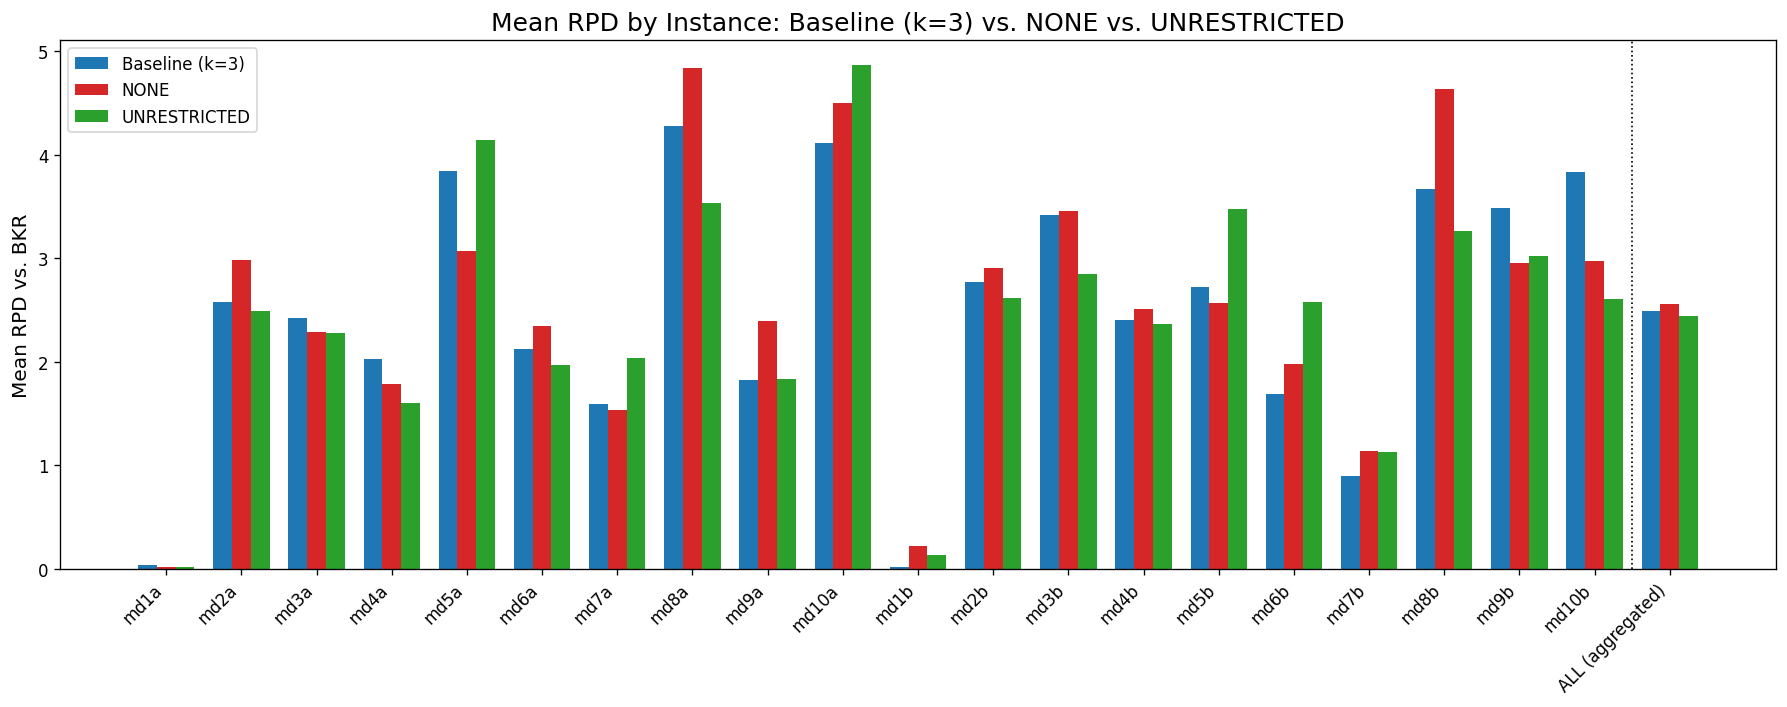

In [9]:
# ---------------------------------------------------------
# Grouped bar chart: mean RPD per instance (+ aggregate), one group per variant
# ---------------------------------------------------------

plot_df = main_table.copy()
x_labels = plot_df["instance"].tolist()
x = np.arange(len(x_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(15, 6))

for i, v in enumerate(VARIANT_ORDER):
    ax.bar(x + (i - 1) * width, plot_df[f"{v} - RPD (%)"], width, label=v, color=VARIANT_COLORS[v])

ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=45, ha="right")
ax.axvline(len(x_labels) - 1.5, color="black", linewidth=1, linestyle=":")
ax.set_ylabel("Mean RPD vs. BKR")
ax.set_title("Mean RPD by Instance: Baseline (k=3) vs. NONE vs. UNRESTRICTED")
ax.legend()

plt.tight_layout()
plt.show()


## 6. Aggregate convergence comparison

Normalized search progress vs. median best-feasible RPD (against the BKR),
pooled across all instances and seeds for each variant.

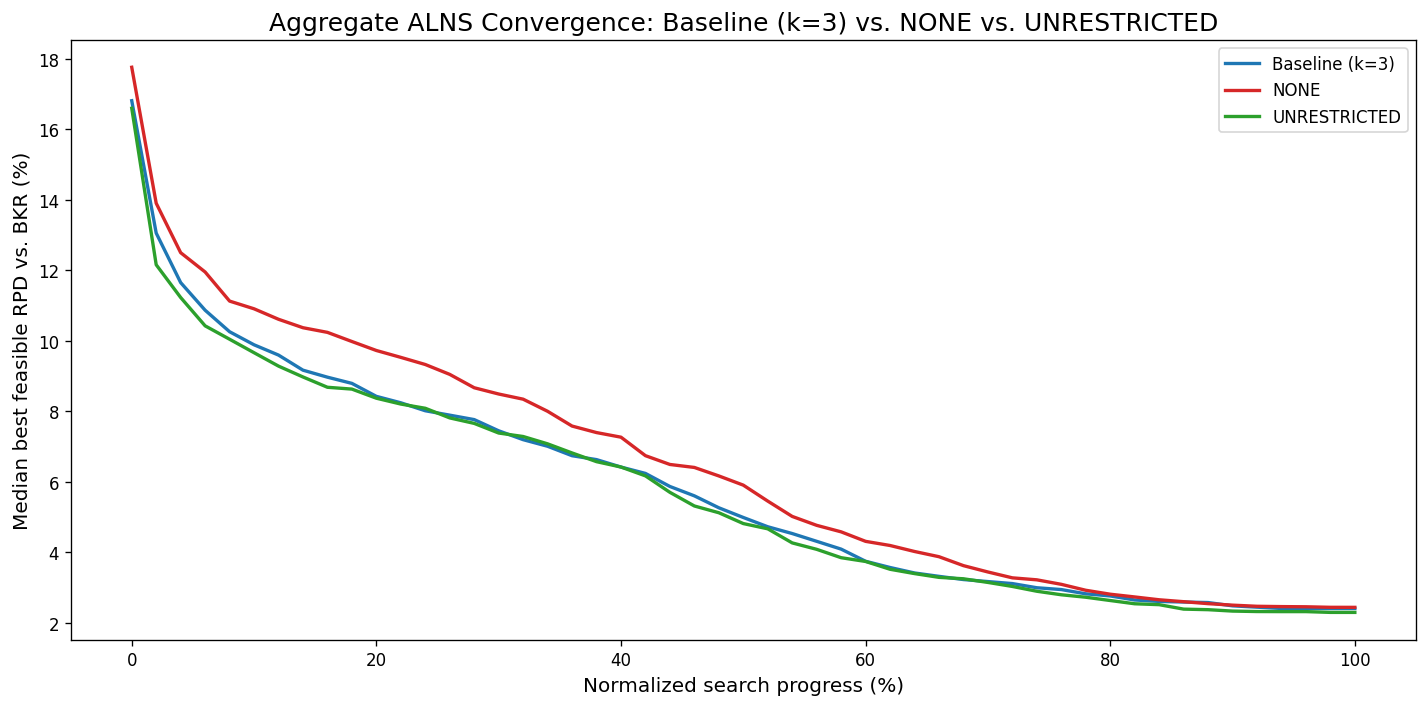

In [10]:
# ---------------------------------------------------------
# Aggregate, normalized convergence curves for the three variants
# ---------------------------------------------------------

conv_for_curve = df_conv_all.merge(bkr_reference, on="instance", how="left")
conv_for_curve["feasible_RPD"] = (
    100 * (conv_for_curve["best_feasible_obj"] - conv_for_curve["bkr"]) / conv_for_curve["bkr"]
)
conv_for_curve["iteration_progress"] = (
    conv_for_curve.groupby("run_id")["iteration"].transform(lambda x: 100 * x / max(x.max(), 1))
)
conv_for_curve["progress_bin"] = np.floor(conv_for_curve["iteration_progress"] / 2) * 2

aggregate_curve = (
    conv_for_curve.dropna(subset=["feasible_RPD"])
    .groupby(["variant", "progress_bin"])["feasible_RPD"]
    .median()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))
for v in VARIANT_ORDER:
    g = aggregate_curve[aggregate_curve["variant"] == v]
    ax.plot(g["progress_bin"], g["feasible_RPD"], label=v, color=VARIANT_COLORS[v])

ax.set_xlabel("Normalized search progress (%)")
ax.set_ylabel("Median best feasible RPD vs. BKR (%)")
ax.set_title("Aggregate ALNS Convergence: Baseline (k=3) vs. NONE vs. UNRESTRICTED")
ax.legend()

plt.tight_layout()
plt.show()


In [11]:
# ---------------------------------------------------------
# Table: Mean Best Objective at Time Cutoffs, ALL instances
#   Baseline (k=3) | NONE | UNRESTRICTED
# ---------------------------------------------------------

TIME_CUTOFFS = [1, 2, 5, 15, 30, 60]


def collect_objective_at_cutoffs(df_conv, time_points):
    """
    For every run (instance, variant, seed) and every cutoff t, take the state of the
    last logged iteration with elapsed_time <= t:
      - best_feasible_obj if a feasible solution exists, else best_obj (flagged infeasible).
    Returns a long dataframe (one row per run x cutoff) with the objective and its RPD (%)
    against the BKR reference per instance.
    """
    records = []
    df_sorted = df_conv.sort_values(["instance", "variant", "seed", "elapsed_time"])

    for (instance, variant, seed), g in df_sorted.groupby(["instance", "variant", "seed"], sort=False):
        times = g["elapsed_time"].to_numpy()
        feas = g["best_feasible_obj"].to_numpy()
        best = g["best_obj"].to_numpy()

        for t in time_points:
            idx = np.searchsorted(times, t, side="right") - 1
            if idx < 0:
                continue
            if not np.isnan(feas[idx]):
                val, is_feas = feas[idx], True
            elif not np.isnan(best[idx]):
                val, is_feas = best[idx], False
            else:
                continue
            records.append((instance, variant, seed, t, val, is_feas))

    out = pd.DataFrame(
        records, columns=["instance", "variant", "seed", "t", "obj", "is_feasible"]
    )

    # RPD vs. BKR
    out = out.merge(bkr_reference, on="instance", how="left")
    out["rpd"] = 100 * (out["obj"] - out["bkr"]) / out["bkr"]
    return out


def format_cell(mean_val, any_feasible):
    if pd.isna(mean_val):
        return "N/A"
    return f"{mean_val:.2f}" if any_feasible else f"{mean_val:.2f}*"


def build_intra_time_table(df_conv, variants, time_points):
    long_df = collect_objective_at_cutoffs(df_conv, time_points)

    # Per instance x variant x cutoff: mean over seeds, asterisk if no seed feasible yet
    cell = (
        long_df.groupby(["instance", "variant", "t"])
        .agg(mean_obj=("rpd", "mean"), any_feas=("is_feasible", "any"))
        .reset_index()
    )
    cell["text"] = [format_cell(m, f) for m, f in zip(cell["mean_obj"], cell["any_feas"])]

    table = cell.pivot(index="instance", columns=["variant", "t"], values="text")

    # Aggregate row: pooled mean over all runs (all instances, all seeds)
    agg = (
        long_df.groupby(["variant", "t"])
        .agg(mean_obj=("rpd", "mean"), any_feas=("is_feasible", "any"))
    )
    agg_row = {
        (v, t): format_cell(agg.loc[(v, t), "mean_obj"], agg.loc[(v, t), "any_feas"])
        if (v, t) in agg.index else "N/A"
        for v in variants for t in time_points
    }

    # Column order: variant-major, then time
    ordered_cols = [(v, t) for v in variants for t in time_points]
    table = table.reindex(columns=pd.MultiIndex.from_tuples(ordered_cols, names=["variant", "t (s)"]))
    table = table.fillna("N/A")

    # Row order: regime (A, then B), then size
    order = sorted(
        table.index,
        key=lambda s: (s[-1].upper(), int(re.search(r"md(\d+)", s).group(1))),
    )
    table = table.loc[order]

    table.loc["ALL (pooled mean)"] = pd.Series(agg_row)[ordered_cols].to_numpy()
    return table


df_intra_time_table = build_intra_time_table(df_conv_all, VARIANT_ORDER, TIME_CUTOFFS)

display(Markdown(
    "### Mean RPD (%) over Time, All Instances (20 Seeds): "
    "Baseline (k=3) vs. NONE vs. UNRESTRICTED"
))
display(df_intra_time_table)
display(Markdown(
    "*RPD is relative to the BKR objective per instance. "
    "An asterisk (`*`) means no seed had found a feasible solution yet at that cutoff.*"
))

df_intra_time_table.to_csv(COMPARISON_DIR / "time_cutoff_table.csv")

### Mean RPD (%) over Time, All Instances (20 Seeds): Baseline (k=3) vs. NONE vs. UNRESTRICTED

variant           Baseline (k=3)                                          \
t (s)                         1         2       5       15     30     60   
instance                                                                   
md1a                        2.95      2.04    0.83    0.11   0.11   0.04   
md2a                       18.09     14.90   10.11    7.87   6.95   5.61   
md3a                       26.54     22.10   16.30   11.79  10.52   8.83   
md4a                       33.14     25.45   18.19   13.96  11.84  10.29   
md5a                      203.95     66.02   33.70   25.06  22.09  20.60   
md6a                     319.86*    102.01   39.22   25.61  21.85  19.44   
md7a                       15.89     12.02   10.22    6.35   5.40   3.13   
md8a                      422.99    240.21   59.34   37.63  26.80  22.45   
md9a                       49.53     30.81   22.20   15.97  13.81  11.84   
md10a                   2260.75*  1070.38*  343.14  119.57  72.31  54.69   
md1b                        3.30      2.52    1.27    0.04   0.02   0.02   
md2b                       16.47     13.01   10.89    8.16   6.78   5.97   
md3b                       32.18     25.38   19.51   14.50  12.64  10.39   
md4b                       47.53     29.77   20.92   15.95  14.24  12.77   
md5b                       97.20     47.99   31.34   22.15  19.53  16.87   
md6b                       92.45     60.82   35.14   21.44  17.57  15.42   
md7b                        7.84      6.40    4.85    2.79   2.06   1.29   
md8b                      319.51    184.49   50.54   37.44  29.46  26.00   
md9b                      173.24     50.84   32.02   25.61  21.35  18.37   
md10b                    895.08*   300.63*   58.17   35.34  29.25  26.19   
ALL (pooled mean)         180.95    115.39   40.90   22.37  17.23  14.51   

variant                NONE                                               \
t (s)                    1         2        5        15       30      60   
instance                                                                   
md1a                   3.11      2.26     1.00     0.23     0.03    0.02   
md2a                  24.41     20.40    14.00    10.55     8.97    6.93   
md3a                  33.55     23.30    17.11    13.94    12.23    9.75   
md4a                  37.31     28.80    19.48    14.58    12.47   10.63   
md5a                386.70*    135.54    49.95    29.39    25.02   22.19   
md6a                656.62*    207.77    52.04    32.87    26.67   22.00   
md7a                  16.91     14.53    10.85     7.21     4.30    3.18   
md8a               1014.23*   451.74*  209.65*    73.26    53.25   36.92   
md9a                  57.85     31.98    24.00    17.89    14.15   12.23   
md10a              3342.57*  2265.61*  875.67*  350.89*  204.47*  121.48   
md1b                   3.92      2.54     1.40     0.31     0.22    0.22   
md2b                  19.33     14.42    11.19     8.84     7.86    6.39   
md3b                  35.54     28.31    21.20    15.52    13.68   11.83   
md4b                  54.51     32.18    23.41    17.92    15.63   13.76   
md5b                 182.51     59.22    37.26    25.57    21.40   18.37   
md6b                304.69*     93.71    37.57    24.74    19.99   18.01   
md7b                   8.42      7.02     5.30     3.25     2.31    1.40   
md8b                943.15*   556.20*   234.47    78.93    63.90   46.77   
md9b                386.51*     95.26    42.90    30.87    26.84   24.45   
md10b              1773.56*   732.57*   133.05    43.48    37.06   32.29   
ALL (pooled mean)    366.30    240.17    91.07    40.01    28.52   20.94   

variant           UNRESTRICTED                                         
t (s)                       1        2        5      15     30     60  
instance                                                               
md1a                      3.05     2.15     1.02   0.17   0.06   0.02  
md2a                     18.85    14.75    11.44   8.42   6.60

*RPD is relative to the BKR objective per instance. An asterisk (`*`) means no seed had found a feasible solution yet at that cutoff.*

In [12]:
long_df = collect_objective_at_cutoffs(df_conv_all, TIME_CUTOFFS)

# Mean best objective, pooled over all instances and seeds
summary_obj = (
    long_df.groupby(["variant", "t"])["rpd"].mean()
    .unstack("t")
    .reindex(index=VARIANT_ORDER, columns=TIME_CUTOFFS)
)

# Share of runs that already have a feasible solution at each cutoff
full_grid = pd.MultiIndex.from_product(
    [VARIANT_ORDER, EXPECTED_INSTANCES, EXPECTED_SEEDS, TIME_CUTOFFS],
    names=["variant", "instance", "seed", "t"],
)
summary_feas = (
    long_df.set_index(["variant", "instance", "seed", "t"])["is_feasible"]
    .reindex(full_grid, fill_value=False)
    .groupby(["variant", "t"]).mean().mul(100)
    .unstack("t")
    .reindex(index=VARIANT_ORDER, columns=TIME_CUTOFFS)
)

summary_obj.index.name = summary_feas.index.name = "Variant"
summary_obj.columns = summary_feas.columns = [f"{t}s" for t in TIME_CUTOFFS]

display(Markdown("### Mean RPD (%) over Time (pooled over all instances and seeds)"))
display(
    summary_obj.style
    .format("{:.2f}")
    .highlight_min(axis=0, props="font-weight: bold; background-color: #d4edda;")
    .set_caption("RPD vs. joint best-known; lower is better. Best variant per cutoff is highlighted.")
)

display(Markdown("### Runs with a Feasible Solution at Each Cutoff (%)"))
display(
    summary_feas.style
    .format("{:.2f}")
    .highlight_max(axis=0, props="font-weight: bold; background-color: #d4edda;")
)

summary_obj.to_csv(COMPARISON_DIR / "time_cutoff_summary_objective.csv")
summary_feas.to_csv(COMPARISON_DIR / "time_cutoff_summary_feasible_pct.csv")

### Mean RPD (%) over Time (pooled over all instances and seeds)

,1s,2s,5s,15s,30s,60s
Variant,,,,,,
Baseline (k=3),180.95,115.39,40.90,22.37,17.23,14.51
NONE,366.30,240.17,91.07,40.01,28.52,20.94
UNRESTRICTED,157.91,102.44,38.56,20.00,15.83,13.49


### Runs with a Feasible Solution at Each Cutoff (%)

,1s,2s,5s,15s,30s,60s
Variant,,,,,,
Baseline (k=3),58.75,74.75,89.75,94.25,96.25,98.00
NONE,52.50,64.00,78.25,88.00,90.50,93.75
UNRESTRICTED,61.00,76.75,90.75,96.00,97.50,98.50


## 7. Export tables

In [13]:
# ---------------------------------------------------------
# Export the two tables for direct use in the paper
# ---------------------------------------------------------

main_table.to_csv(COMPARISON_DIR / "main_comparison_table.csv", index=False)
win_summary.to_csv(COMPARISON_DIR / "win_summary.csv")

print(f"Exported tables to: {COMPARISON_DIR.resolve()}")


Exported tables to: /home/guillem/MD-DARP-Research/experiments/results/intra_route
